# 02 — Data Cleaning and Normalization

In this section, we prepare the raw Digikala reviews dataset for text analysis and machine learning after normalizing.

### Objectives
- Normalize Persian text by standardizing Arabic and Persian characters, handling half-spaces and whitespace, removing punctuation and diacritics, and reducing repeated characters.
- Preserve the original text and store the normalized text in a separate column.
- Re-evaluate text duplicates after normalization.
-

### Notes
- The original dataset remains unchanged.
- Large CSV files are processed in chunks to reduce memory usage.
- Missing recommendation labels are kept distinct from `no_idea`.
- Duplicate or similar comments are investigated before deciding whether any records should be removed.


In [1]:
from pathlib import Path
from collections import Counter, defaultdict
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sqlite3, tempfile, os, json, math, hashlib
from IPython.display import display
import csv
import json
import shutil


RANDOM_SEED = 42
CHUNK_SIZE = 100_000
DATA_DIR = Path("../data")
COMMENTS_PATH = DATA_DIR / "digikala-comments.csv"
PRODUCTS_PATH = DATA_DIR / "digikala-products.csv"

if not COMMENTS_PATH.exists():
    raise FileNotFoundError(f"Comments file not found: {COMMENTS_PATH.resolve()}")
if not PRODUCTS_PATH.exists():
    raise FileNotFoundError(f"Products file not found: {PRODUCTS_PATH.resolve()}")

print(f"Working directory: {Path.cwd()}")
for path in [COMMENTS_PATH, PRODUCTS_PATH]:
    print(f"{path.name}: {path.stat().st_size / (1024**2):,.2f} MiB")


Working directory: d:\AI Bootcamp_M Sharif\digikala_reviews_project\notebooks
digikala-comments.csv: 1,219.30 MiB
digikala-products.csv: 246.75 MiB


# PHASE 1 : Normalizing Review Body

In [4]:
import re
import unicodedata
import pandas as pd


# Arabic-to-Persian character mapping
CHAR_MAP = str.maketrans({
    "ي": "ی",
    "ى": "ی",
    "ك": "ک",
    "ۀ": "ه",
    "ة": "ه",
    "ؤ": "و",
    "إ": "ا",
    "أ": "ا",
    "ٱ": "ا",
})

# Convert Persian and Arabic digits to English digits
DIGIT_MAP = str.maketrans(
    "۰۱۲۳۴۵۶۷۸۹٠١٢٣٤٥٦٧٨٩",
    "01234567890123456789"
)

# Remove Arabic diacritics, tatweel, and invisible formatting characters
DIACRITICS_RE = re.compile(
    r"[\u0610-\u061A\u064B-\u065F\u0670\u06D6-\u06ED]"
)

INVISIBLE_RE = re.compile(
    r"[\u200B\u200D-\u200F\u202A-\u202E\u2060\uFEFF]"
)

TATWEEL = "\u0640"

# Match repeated Persian/Arabic or Latin letters.
# Three or more consecutive occurrences become one.
REPEATED_LETTERS_RE = re.compile(
    r"([^\W\d_])\1{2,}",
    flags=re.UNICODE
)

# Keep letters, digits, whitespace, and ZWNJ (half-space).
# Other punctuation and symbols become spaces.
PUNCTUATION_RE = re.compile(
    r"[^\w\s\u200c]|_",
    flags=re.UNICODE
)

# Normalize whitespace around half-spaces
HALF_SPACE_RE = re.compile(r"\s*\u200c\s*")

# Collapse consecutive whitespace
WHITESPACE_RE = re.compile(r"\s+")


def normalize_persian_text(text):
    """
    Normalize Persian text for NLP preprocessing.

    Returns an empty string for missing or empty input.
    """

    if pd.isna(text):
        return ""

    text = str(text)

    # Unicode normalization
    text = unicodedata.normalize("NFC", text)

    # Standardize Arabic/Persian letters and digits
    text = text.translate(CHAR_MAP)
    text = text.translate(DIGIT_MAP)

    # Remove diacritics, tatweel, and invisible formatting characters
    text = DIACRITICS_RE.sub("", text)
    text = text.replace(TATWEEL, "")
    text = INVISIBLE_RE.sub("", text)

    # Reduce elongated words: عالییییی -> عالی
    text = REPEATED_LETTERS_RE.sub(r"\1", text)

    # Replace punctuation with spaces instead of joining words
    text = PUNCTUATION_RE.sub(" ", text)

    # Normalize half-spaces
    text = HALF_SPACE_RE.sub("\u200c", text)

    # Normalize whitespace
    text = WHITESPACE_RE.sub(" ", text).strip()

    return text


In [5]:
NORMALIZED_PATH = Path("../data/digikala-comments-normalized.csv")
SAMPLE_SIZE = 10

first_chunk = True
changed_samples = []
changed_count = 0
total_rows = 0

for chunk in pd.read_csv(
    COMMENTS_PATH,
    chunksize=CHUNK_SIZE,
    dtype={
        "body": "string",
        "recommendation_status": "string"
    },
    encoding="utf-8-sig",
    low_memory=False
):
    total_rows += len(chunk)

    # Preserve the original text
    original = chunk["body"].fillna("")

    # Normalize text only once
    normalized = original.map(normalize_persian_text)

    # Find rows where normalization changed the text
    changed_mask = original.ne(normalized)
    changed_count += int(changed_mask.sum())

    # Collect up to 10 changed examples
    remaining = SAMPLE_SIZE - sum(
        len(sample) for sample in changed_samples
    )

    if remaining > 0 and changed_mask.any():
        sample = pd.DataFrame({
            "original_text": original[changed_mask],
            "normalized_text": normalized[changed_mask],
            "recommendation_status": (
                chunk.loc[changed_mask, "recommendation_status"]
                .fillna("<MISSING LABEL>")
                .replace("", "<BLANK LABEL>")
            )
        })

        changed_samples.append(
            sample.head(remaining)
        )

    # Add normalized text as a separate column
    chunk["body_normalized"] = normalized

    # Save incrementally without loading the whole dataset into RAM
    chunk.to_csv(
        NORMALIZED_PATH,
        index=False,
        mode="w" if first_chunk else "a",
        header=first_chunk,
        encoding="utf-8-sig"
    )

    first_chunk = False

# Display summary
print(f"Total rows processed: {total_rows:,}")
print(f"Rows changed by normalization: {changed_count:,}")
print(f"Normalized dataset saved to: {NORMALIZED_PATH}")

# Display changed examples
if changed_samples:
    changed_df = pd.concat(
        changed_samples,
        ignore_index=True
    )

    pd.set_option("display.max_colwidth", None)
    display(changed_df)
else:
    print("No text changes were found during normalization.")

Total rows processed: 6,156,289
Rows changed by normalization: 2,642,908
Normalized dataset saved to: ..\data\digikala-comments-normalized.csv


,original_text,normalized_text,recommendation_status
0,به درد نمیخوره,به درد نمیخوره,not_recommended
1,بسته بندیش خوب بود\r\n کاربرد و کیفیتشم خیلی خوبه من برای روغن زدم به مژه و لیفت ابرو خریدم,بسته بندیش خوب بود کاربرد و کیفیتشم خیلی خوبه من برای روغن زدم به مژه و لیفت ابرو خریدم,recommended
2,به نظرم خوبه فقط یکم ظریفه. از رنگش خوشم اومد من برای صابون ابرو استفاده میکنم راضی ام,به نظرم خوبه فقط یکم ظریفه از رنگش خوشم اومد من برای صابون ابرو استفاده میکنم راضی ام,recommended
3,قبلا هم استفاده کردم اگه بلد باشین کار کردن باهاش رو \r\nبرای ی پاکسازی پوست سطحی توی خونه عالیه,قبلا هم استفاده کردم اگه بلد باشین کار کردن باهاش رو برای ی پاکسازی پوست سطحی توی خونه عالیه,recommended
4,اندازش کوچیکه بدرد رنگ مو نمیخوره,اندازش کوچیکه بدرد رنگ مو نمیخوره,not_recommended
5,خوب بود بخرید قشنگه,خوب بود بخرید قشنگه,recommended
6,سالم بود،شستنش راحته،واسه ماسک گذاشتن خیلی ایده ی خوبیه،از اسراف و کثیف کاری قشنگ جلوگیری میکنه.,سالم بود شستنش راحته واسه ماسک گذاشتن خیلی ایده ی خوبیه از اسراف و کثیف کاری قشنگ جلوگیری میکنه,recommended
7,خیلی عالی بود ، کاربردیه ، دیگه لازم نیست جوشا رو دستکاری کرد ، با این پیلینگ خیلی راحت میشه تخلیه کرد,خیلی عالی بود کاربردیه دیگه لازم نیست جوشا رو دستکاری کرد با این پیلینگ خیلی راحت میشه تخلیه کرد,recommended
8,کیفیت چاپ خوب بود. اما چسب ها فاسد بودند,کیفیت چاپ خوب بود اما چسب ها فاسد بودند,no_idea
9,به نظرم چیز خوب و خفنیه مخصوصا با قیمت ۱۰ ت \r\nمن فکر میکردم خیلی کوچیک باشه ولی اندازش کاملا اوکی بود و مشکلی نداشت \r\nضایعات هم نداشت که به مو آسیب بزنه \r\nبرای کسی که موهاش فرفریه و میخواد فرم خوبی به موهاش بده عالیه,به نظرم چیز خوب و خفنیه مخصوصا با قیمت 10 ت من فکر میکردم خیلی کوچیک باشه ولی اندازش کاملا اوکی بود و مشکلی نداشت ضایعات هم نداشت که به مو آسیب بزنه برای کسی که موهاش فرفریه و میخواد فرم خوبی به موهاش بده عالیه,recommended


In [6]:
# Confirm schema and report file metadata using parser-based row counts, not physical lines.
assert COMMENTS_PATH.exists(), f"Missing file: {COMMENTS_PATH.resolve()}"
assert PRODUCTS_PATH.exists(), f"Missing file: {PRODUCTS_PATH.resolve()}"
comments_cols = pd.read_csv(COMMENTS_PATH, nrows=0).columns.tolist()
products_cols = pd.read_csv(PRODUCTS_PATH, nrows=0).columns.tolist()
print("Comments file bytes:", COMMENTS_PATH.stat().st_size)
print("Products file bytes:", PRODUCTS_PATH.stat().st_size)
print("Comments columns:", len(comments_cols), comments_cols)
print("Products columns:", len(products_cols), products_cols)

Comments file bytes: 1278526959
Products file bytes: 258733765
Comments columns: 15 ['id', 'title', 'body', 'created_at', 'rate', 'recommendation_status', 'is_buyer', 'product_id', 'advantages', 'disadvantages', 'likes', 'dislikes', 'seller_title', 'seller_code', 'true_to_size_rate']
Products columns: 12 ['id', 'title_fa', 'Rate', 'Rate_cnt', 'Category1', 'Category2', 'Brand', 'Price', 'Seller', 'Is_Fake', 'min_price_last_month', 'sub_category']


### Duplicate IDs, repeated text, conflicting labels after normalization 

ID frequency summary (distinct repeated IDs / rows within repeated IDs / extra duplicate occurrences):


,unique_ids,distinct_repeated_ids,rows_in_repeated_ids,extra_duplicate_occurrences
0,6153060,3226,6455,3229


Repeated non-empty body summary:


,unique_bodies,distinct_repeated_bodies,rows_in_repeated_bodies,extra_repetitions,max_repetitions
0,3928203,192690,2419535,2226845,159155


Identical bodies that have multiple raw label values: 75138
Top repeated bodies:


,body,n
0,عالی,159155
1,خوب بود,99900
2,خوبه,91622
3,خوب,74632
4,عالی بود,36623
5,عالیه,28127
6,خیلی خوب بود,19087
7,پیشنهاد میکنم,16246
8,معمولی,16134
9,خیلی خوبه,15570


Top identical-text label conflicts:


,body,label_counts
0,عالی,<MISSING>: 43995 | no_idea: 764 | not_recommended: 340 | recommended: 114056
1,خوب بود,<MISSING>: 22250 | no_idea: 5044 | not_recommended: 285 | recommended: 72321
2,خوبه,<MISSING>: 22956 | no_idea: 4523 | not_recommended: 267 | recommended: 63876
3,خوب,<MISSING>: 21981 | no_idea: 3525 | not_recommended: 243 | recommended: 48883
4,عالی بود,<MISSING>: 8599 | no_idea: 189 | not_recommended: 77 | recommended: 27758
5,عالیه,<MISSING>: 6258 | no_idea: 152 | not_recommended: 49 | recommended: 21668
6,خیلی خوب بود,<MISSING>: 2397 | no_idea: 130 | not_recommended: 33 | recommended: 16527
7,پیشنهاد میکنم,<MISSING>: 1912 | no_idea: 206 | not_recommended: 25 | recommended: 14103
8,معمولی,<MISSING>: 3739 | no_idea: 7279 | not_recommended: 455 | recommended: 4661
9,خیلی خوبه,<MISSING>: 2997 | no_idea: 115 | not_recommended: 30 | recommended: 12428


Comments per product_id distribution:


,comments_per_product
count,331599.000000
mean,18.565463
std,40.934097
min,1.000000
50%,4.000000
75%,13.000000
90%,46.000000
95%,110.000000
99%,200.000000
max,400.000000


Top 1 products share: 0.01%
Top 10 products share: 0.05%
Top 100 products share: 0.36%
Top 1000 products share: 3.32%


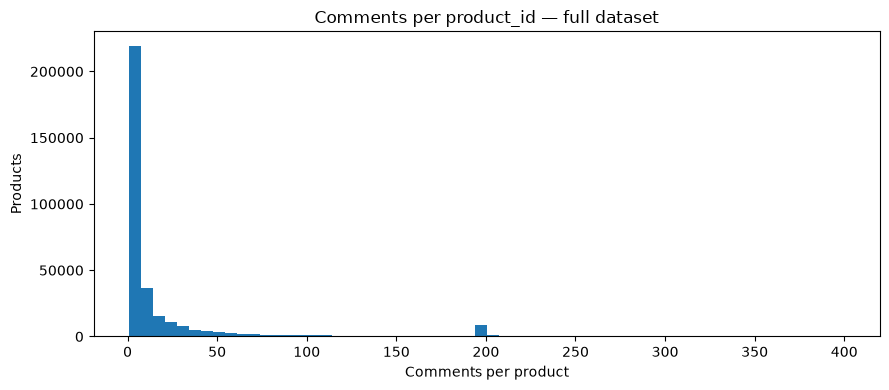

In [7]:
# Disk-backed exact frequency tables avoid storing millions of unique text keys in RAM.
tmpdb=tempfile.NamedTemporaryFile(suffix=".sqlite",delete=False); dbpath=tmpdb.name; tmpdb.close()
con=sqlite3.connect(dbpath)
con.execute("CREATE TABLE ids (v TEXT PRIMARY KEY,n INTEGER NOT NULL)")
con.execute("CREATE TABLE bodies (v TEXT PRIMARY KEY,n INTEGER NOT NULL)")
con.execute("CREATE TABLE body_labels (body TEXT,label TEXT,n INTEGER NOT NULL,PRIMARY KEY(body,label))")
con.execute("CREATE TABLE product_freq (v TEXT PRIMARY KEY,n INTEGER NOT NULL)")
for chunk in pd.read_csv(NORMALIZED_PATH,chunksize=CHUNK_SIZE,dtype={"id":"string","product_id":"string","recommendation_status":"string"},low_memory=False,usecols=["id","body_normalized","product_id","recommendation_status"]):
    for col,table in [("id","ids"),("product_id","product_freq")]:
        vc=chunk[col].dropna().astype(str).value_counts()
        con.executemany(f"INSERT INTO {table}(v,n) VALUES (?,?) ON CONFLICT(v) DO UPDATE SET n=n+excluded.n",[(k,int(v)) for k,v in vc.items()])
    body=chunk["body_normalized"].fillna("").astype(str); label=chunk["recommendation_status"].fillna("<MISSING>").astype(str).str.strip().replace("","<BLANK>")
    valid=body.str.strip().ne("")
    vc=body[valid].value_counts()
    con.executemany("INSERT INTO bodies(v,n) VALUES (?,?) ON CONFLICT(v) DO UPDATE SET n=n+excluded.n",[(k,int(v)) for k,v in vc.items()])
    pairs=pd.DataFrame({"body":body[valid],"label":label[valid]}).value_counts()
    con.executemany("INSERT INTO body_labels(body,label,n) VALUES (?,?,?) ON CONFLICT(body,label) DO UPDATE SET n=n+excluded.n",[(b,l,int(v)) for (b,l),v in pairs.items()])
con.commit()

pd.set_option("display.max_colwidth", None)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", None)


print("ID frequency summary (distinct repeated IDs / rows within repeated IDs / extra duplicate occurrences):")
display(pd.read_sql_query("SELECT COUNT(*) unique_ids, SUM(n>1) distinct_repeated_ids, SUM(CASE WHEN n>1 THEN n ELSE 0 END) rows_in_repeated_ids, SUM(n-1) extra_duplicate_occurrences FROM ids",con))
print("Repeated non-empty body summary:")
display(pd.read_sql_query("SELECT COUNT(*) unique_bodies, SUM(n>1) distinct_repeated_bodies, SUM(CASE WHEN n>1 THEN n ELSE 0 END) rows_in_repeated_bodies, SUM(n-1) extra_repetitions, MAX(n) max_repetitions FROM bodies",con))
print("Identical bodies that have multiple raw label values:",con.execute("SELECT COUNT(*) FROM (SELECT body FROM body_labels GROUP BY body HAVING COUNT(DISTINCT label)>1)").fetchone()[0])
print("Top repeated bodies:"); display(pd.read_sql_query("SELECT v AS body,n FROM bodies WHERE n>1 ORDER BY n DESC LIMIT 20",con))
print("Top identical-text label conflicts:")
display(pd.read_sql_query("SELECT body,GROUP_CONCAT(label || ': ' || n,' | ') label_counts FROM body_labels GROUP BY body HAVING COUNT(DISTINCT label)>1 ORDER BY SUM(n) DESC LIMIT 20",con))
product_freq=np.array([r[0] for r in con.execute("SELECT n FROM product_freq")],dtype=np.int64)
print("Comments per product_id distribution:"); display(pd.Series(product_freq,name="comments_per_product").describe(percentiles=[.5,.75,.9,.95,.99]).to_frame())
for k in [1,10,100,1000]:
    top=int(np.sort(product_freq)[-min(k,len(product_freq)):].sum())
    print(f"Top {k} products share: {100*top/max(int(product_freq.sum()),1):.2f}%")
plt.figure(figsize=(9,4)); plt.hist(product_freq,bins=60); plt.title("Comments per product_id — full dataset"); plt.xlabel("Comments per product"); plt.ylabel("Products"); plt.tight_layout(); plt.show()

### Full-data text-length statistics and class comparison after normalizing

,measure,count,mean,median,std,min,p75,p90,p95,p99,max,very_short,very_long
0,characters,6156289,47.415377,28.0,63.134302,0,56.0,104.0,150.0,291.0,3999,886347,56813
1,words,6156289,10.082287,6.0,13.356737,0,12.0,22.0,32.0,62.0,908,1028466,15920


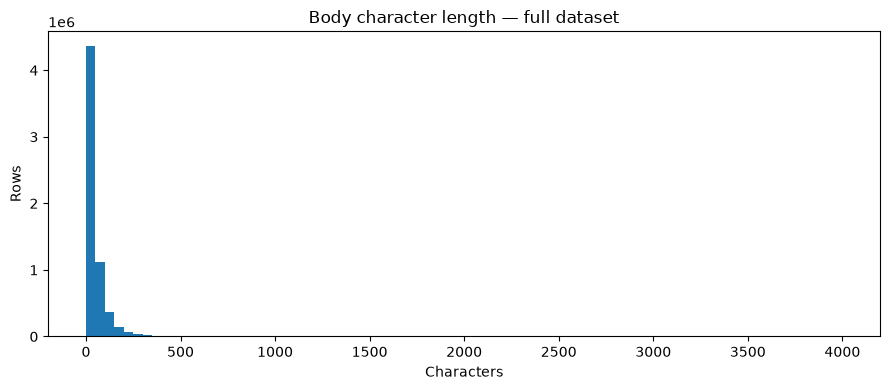

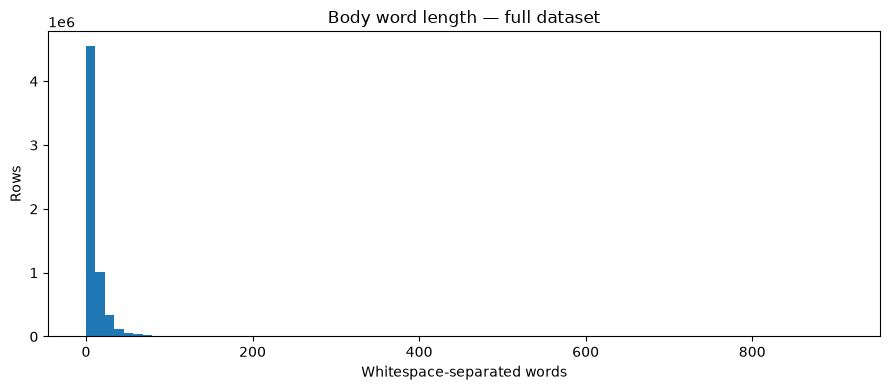

,label,count,mean_chars,median_chars,p90_chars,p95_chars
1,recommended,4162839,43.306271,26.0,94.0,134.0
2,<MISSING>,894426,45.541905,25.0,103.0,152.0
3,no_idea,594121,58.235994,37.0,127.0,177.0
0,not_recommended,504903,71.880419,47.0,156.0,213.0


In [8]:
char_all=[]
word_all=[]
class_lengths={}
for chunk in pd.read_csv(
    NORMALIZED_PATH,
    chunksize=CHUNK_SIZE,
    usecols=["body_normalized","recommendation_status"],
    dtype={"recommendation_status":"string"},
    low_memory=False
    ):
        body=chunk["body_normalized"].fillna("").astype(str)
        chars=body.str.len().to_numpy(dtype=np.int32)
        words=body.str.split().str.len().to_numpy(dtype=np.int32)
        char_all.append(chars); word_all.append(words)
        labels=chunk["recommendation_status"].fillna("<MISSING>").str.strip().replace("","<BLANK>")
        for lab in labels.unique():
            mask=labels.eq(lab).to_numpy()
            class_lengths.setdefault(str(lab),[]).append(chars[mask])
chars=np.concatenate(char_all); words=np.concatenate(word_all)
def describe_lengths(x,name):
    s=pd.Series(x)
    return {"measure":name,"count":len(s),"mean":s.mean(),"median":s.median(),"std":s.std(),"min":s.min(),"p75":s.quantile(.75),"p90":s.quantile(.90),"p95":s.quantile(.95),"p99":s.quantile(.99),"max":s.max(),"very_short":int((s<=10).sum() if name=="characters" else (s<=2).sum()),"very_long":int((s>=300).sum() if name=="characters" else (s>=100).sum())}
display(pd.DataFrame([describe_lengths(chars,"characters"),describe_lengths(words,"words")]))
plt.figure(figsize=(9,4)); plt.hist(chars,bins=80); plt.title("Body character length — full dataset"); plt.xlabel("Characters"); plt.ylabel("Rows"); plt.tight_layout(); plt.show()
plt.figure(figsize=(9,4)); plt.hist(words,bins=80); plt.title("Body word length — full dataset"); plt.xlabel("Whitespace-separated words"); plt.ylabel("Rows"); plt.tight_layout(); plt.show()
class_summary=[]
for lab,arrs in class_lengths.items():
    x=np.concatenate(arrs)
    class_summary.append({"label":lab,"count":len(x),"mean_chars":float(x.mean()),"median_chars":float(np.median(x)),"p90_chars":float(np.quantile(x,.9)),"p95_chars":float(np.quantile(x,.95))})
class_summary=pd.DataFrame(class_summary).sort_values("count",ascending=False); display(class_summary)

# PHASE 2 : Cleaning Data

In [9]:
# Input and output files
NORMALIZED_PATH = Path("../data/digikala-comments-normalized.csv")
CLEANED_PATH = Path("../data/digikala-comments-cleaned.csv")

## Step 1 — Removing rows with an empty body

Since the normalization process may convert text consisting solely of spaces, punctuation, or invisible characters into an empty string, the removal process must be based on the `body_normalized` column, rather than just the `body` column.

Removal criteria:
- The `body_normalized` value is an empty string.
- The value consists exclusively of spaces and whitespace characters.
- Missing values ​​(NaN) should also be removed.


In [23]:
# Processing statistics
total_rows = 0
removed_rows = 0
saved_rows = 0
first_chunk = True

if not NORMALIZED_PATH.exists():
    raise FileNotFoundError(f"Input file not found: {NORMALIZED_PATH}")

for chunk in pd.read_csv(
    NORMALIZED_PATH,
    chunksize=CHUNK_SIZE,
    dtype={"body": "string", "body_normalized": "string"},
    encoding="utf-8-sig",
    low_memory=False
):
    total_rows += len(chunk)

    # Identify missing or empty normalized review bodies
    empty_mask = (
        chunk["body_normalized"].isna()
        | chunk["body_normalized"].str.strip().eq("").fillna(False)
    )

    removed_rows += int(empty_mask.sum())

    # Keep rows with non-empty normalized review bodies
    cleaned_chunk = chunk.loc[~empty_mask].copy()
    saved_rows += len(cleaned_chunk)

    # Write each chunk to the same output file
    cleaned_chunk.to_csv(
        CLEANED_PATH,
        index=False,
        mode="w" if first_chunk else "a",
        header=first_chunk,
        encoding="utf-8-sig"
    )

    first_chunk = False

# Handle the unlikely case of an empty input file
if first_chunk:
    empty_df = pd.read_csv(NORMALIZED_PATH, nrows=0, encoding="utf-8-sig")
    empty_df.to_csv(CLEANED_PATH, index=False, encoding="utf-8-sig")

# Display cleaning results
print(f"Total input rows: {total_rows:,}")
print(f"Rows removed due to empty normalized bodies: {removed_rows:,}")
print(f"Rows retained: {saved_rows:,}")
print(f"Output row count check: {total_rows - removed_rows:,}")
print(f"Cleaned dataset saved to: {CLEANED_PATH}")

assert total_rows == removed_rows + saved_rows

Total input rows: 6,156,289
Rows removed due to empty normalized bodies: 1,241
Rows retained: 6,155,048
Output row count check: 6,155,048
Cleaned dataset saved to: ..\data\digikala-comments-cleaned.csv


## Step 2 — Removing exact duplicate records

In this step, we remove duplicate records only when **all columns have exactly the same values**. Records with identical review bodies but different values in other columns are retained.

### Removal criteria
- All column values in a record must match those of an existing record.
- Duplicate records are identified across the entire dataset, including records located in different chunks.
- The first occurrence of each unique record is retained, and subsequent exact duplicates are removed.

### Notes
- The dataset is processed in chunks to reduce memory usage.
- A temporary SQLite database is used to track previously encountered records across chunks.
- The input file remains unchanged, and the deduplicated dataset is saved to a separate output file--> Cleaned File
- The number of input records, removed duplicates, and remaining records is displayed after processing.

In [24]:
# Input and output files
INPUT_PATH = CLEANED_PATH
TEMP_OUTPUT_PATH = INPUT_PATH.with_name(".cleaned_temp.csv")
DB_PATH = INPUT_PATH.with_name(".deduplication_temp.sqlite")

# Processing statistics
total_rows = 0
removed_rows = 0
saved_rows = 0
first_chunk = True
processing_successful = False

if not INPUT_PATH.exists():
    raise FileNotFoundError(f"Input file not found: {INPUT_PATH}")

try:
    # Remove stale temporary files from a previous interrupted run
    if TEMP_OUTPUT_PATH.exists():
        TEMP_OUTPUT_PATH.unlink()

    # Create a fresh temporary database
    if DB_PATH.exists():
        DB_PATH.unlink()

    conn = sqlite3.connect(DB_PATH)

    try:
        conn.execute("""
            CREATE TABLE seen_records (
                signature TEXT PRIMARY KEY
            )
        """)

        for chunk in pd.read_csv(
            INPUT_PATH,
            chunksize=CHUNK_SIZE,
            dtype="string",
            keep_default_na=False,
            encoding="utf-8-sig",
            low_memory=False
        ):
            total_rows += len(chunk)

            signatures = (
                hashlib.sha1(
                    json.dumps(
                        list(row),
                        ensure_ascii=False,
                        separators=(",", ":")
                    ).encode("utf-8")
                ).hexdigest()
                for row in chunk.itertuples(index=False, name=None)
            )

            keep_positions = []
            cursor = conn.cursor()

            for position, signature in enumerate(signatures):
                cursor.execute(
                    "INSERT OR IGNORE INTO seen_records (signature) VALUES (?)",
                    (signature,)
                )

                if cursor.rowcount == 1:
                    keep_positions.append(position)

            unique_chunk = chunk.iloc[keep_positions]

            chunk_removed = len(chunk) - len(unique_chunk)
            removed_rows += chunk_removed
            saved_rows += len(unique_chunk)

            unique_chunk.to_csv(
                TEMP_OUTPUT_PATH,
                index=False,
                mode="w" if first_chunk else "a",
                header=first_chunk,
                encoding="utf-8-sig"
            )

            first_chunk = False

        # Preserve the column headers when the input contains no data rows
        if first_chunk:
            empty_df = pd.read_csv(
                INPUT_PATH,
                nrows=0,
                encoding="utf-8-sig"
            )
            empty_df.to_csv(
                TEMP_OUTPUT_PATH,
                index=False,
                encoding="utf-8-sig"
            )

        conn.commit()
        processing_successful = True

    finally:
        conn.close()

    # Replace the cleaned dataset only after successful processing
    if processing_successful:
        assert total_rows == removed_rows + saved_rows

        TEMP_OUTPUT_PATH.replace(INPUT_PATH)

finally:
    # Remove the temporary database after closing the connection
    if 'conn' in locals() and conn is not None:
        conn.close()

    if DB_PATH.exists():
        try:
            DB_PATH.unlink()
        except PermissionError:
            print(
                "Warning: The temporary database could not be deleted. "
                "Close any remaining database connections and remove it later."
            )

    # Remove incomplete output only if it was not committed
    if not processing_successful and TEMP_OUTPUT_PATH.exists():
        try:
            TEMP_OUTPUT_PATH.unlink()
        except PermissionError:
            print(
                "Warning: The incomplete temporary output could not be deleted."
            )

# Display cleaning results
if processing_successful:
    print(f"Total input rows: {total_rows:,}")
    print(f"Rows removed as exact duplicates: {removed_rows:,}")
    print(f"Rows retained: {saved_rows:,}")
    print(f"Output row count check: {total_rows - removed_rows:,}")
    print(f"Updated cleaned dataset: {INPUT_PATH}")


Total input rows: 6,155,048
Rows removed as exact duplicates: 1,318
Rows retained: 6,153,730
Output row count check: 6,153,730
Updated cleaned dataset: ..\data\digikala-comments-cleaned.csv


## Step 3 — Removing exact duplicate product records

In this step, we remove duplicate records from the Digikala products dataset. A record is considered a duplicate only when **all column values exactly match** those of a previously encountered record.

### Removal criteria
- All column values must match an existing product record.
- Records with the same product name but different values in other columns are retained.
- The first occurrence of each unique record is preserved.

### Notes
- The products CSV file is processed in chunks to reduce memory usage.
- A temporary SQLite database tracks previously encountered records across chunks.
- Empty values are read as empty strings for consistent comparison.
- The original products file remains unchanged, and the deduplicated dataset is saved to a separate output file.
- The total input records, removed duplicates, and remaining records are displayed after processing.

In [12]:
# Input and output files
PRODUCTS_PATH = Path("../data/digikala-products.csv")
PRODUCTS_DEDUPLICATED_PATH = Path("../data/digikala-products-cleaned.csv")
PRODUCTS_TEMP_PATH = PRODUCTS_DEDUPLICATED_PATH.with_name(".products_cleaned_temp.csv")
DB_PATH = Path("../data/.products_deduplication_temp.sqlite")

# Processing statistics
total_rows = 0
removed_rows = 0
saved_rows = 0
first_chunk = True
processing_successful = False
conn = None

if not PRODUCTS_PATH.exists():
    raise FileNotFoundError(f"Products file not found: {PRODUCTS_PATH}")

try:
    for path in [PRODUCTS_TEMP_PATH, DB_PATH]:
        if path.exists():
            path.unlink()

    conn = sqlite3.connect(DB_PATH)
    conn.execute("CREATE TABLE seen_records (signature TEXT PRIMARY KEY)")

    for chunk in pd.read_csv(
        PRODUCTS_PATH,
        chunksize=CHUNK_SIZE,
        dtype="string",
        keep_default_na=False,
        encoding="utf-8-sig",
        low_memory=False
    ):
        total_rows += len(chunk)
        keep_positions = []
        cursor = conn.cursor()

        for position, row in enumerate(chunk.itertuples(index=False, name=None)):
            signature = json.dumps(list(row), ensure_ascii=False, separators=(",", ":"))
            cursor.execute(
                "INSERT OR IGNORE INTO seen_records (signature) VALUES (?)",
                (signature,)
            )
            if cursor.rowcount == 1:
                keep_positions.append(position)

        unique_chunk = chunk.iloc[keep_positions].copy()
        removed_rows += len(chunk) - len(unique_chunk)
        saved_rows += len(unique_chunk)

        unique_chunk.to_csv(
            PRODUCTS_TEMP_PATH,
            index=False,
            mode="w" if first_chunk else "a",
            header=first_chunk,
            encoding="utf-8-sig"
        )
        first_chunk = False

    if first_chunk:
        pd.read_csv(PRODUCTS_PATH, nrows=0, encoding="utf-8-sig").to_csv(
            PRODUCTS_TEMP_PATH, index=False, encoding="utf-8-sig"
        )

    conn.commit()
    conn.close()
    conn = None

    assert total_rows == removed_rows + saved_rows
    PRODUCTS_TEMP_PATH.replace(PRODUCTS_DEDUPLICATED_PATH)
    processing_successful = True

finally:
    if conn is not None:
        conn.close()
    for path in [DB_PATH, PRODUCTS_TEMP_PATH]:
        try:
            path.unlink(missing_ok=True)
        except PermissionError:
            print(f"Warning: Could not remove temporary file: {path}")

if processing_successful:
    print(f"Total input product rows: {total_rows:,}")
    print(f"Exact duplicate product rows removed: {removed_rows:,}")
    print(f"Product rows retained: {saved_rows:,}")
    print(f"Deduplicated products saved to: {PRODUCTS_DEDUPLICATED_PATH}")

Total input product rows: 1,283,496
Exact duplicate product rows removed: 323,129
Product rows retained: 960,367
Deduplicated products saved to: ..\data\digikala-products-cleaned.csv


## Step 4 — Extracting Label-Conflict Groups

This step uses `digikala-comments-cleaned.csv` as the working dataset. The raw comments file and the normalized file are never modified by this or later cleaning steps.

### Conflict definition
- Records are grouped by `body_normalized`.
- Empty normalized bodies are excluded from conflict analysis and removed from the cleaned working dataset.
- Empty or missing `recommendation_status` values are ignored when deciding whether a body has conflicting labels.
- A body is considered conflicting only when it has at least two distinct, non-empty labels.

### Workflow
1. Create a timestamped backup of the current cleaned dataset before changing it.
2. Use SQLite to count labels per normalized body without storing full rows in the database.
3. Stream the dataset a second time, writing conflicting rows to `digikala-label-conflicts.csv` and non-conflicting rows to a temporary cleaned file.
4. Validate row counts and close the database before replacing the cleaned file.
5. Keep the conflict rows outside the main cleaned dataset until they are reviewed and resolved in Step 5.

The conflict file retains the original columns and adds `group_id`, `body_text`, and `label` for review. The `label` helper column mirrors `recommendation_status`; edit `recommendation_status` when making manual corrections.

In [25]:
from pathlib import Path
import sqlite3
import uuid

DB_PATH = Path("../data/.label_conflicts_temp.sqlite")

# ساخت دیتابیس جدید با نام یکتا؛ فایل قبلی دست‌نخورده می‌ماند
NEW_DB_PATH = DB_PATH.with_name(
    f".label_conflicts_temp_{uuid.uuid4().hex[:8]}.sqlite"
)

conn = sqlite3.connect(str(NEW_DB_PATH), timeout=30)

print("اتصال جدید ساخته شد:")
print(NEW_DB_PATH.resolve())

اتصال جدید ساخته شد:
D:\AI Bootcamp_M Sharif\digikala_reviews_project\data\.label_conflicts_temp_13803849.sqlite


In [26]:
import csv
import shutil
import sqlite3
from datetime import datetime
import uuid

# Input and output files
INPUT_PATH = CLEANED_PATH
CONFLICTS_PATH = Path("../data/digikala-label-conflicts.csv")
CONFLICTS_TEMP_PATH = Path("../data/.label_conflicts_temp.csv")
CLEANED_TEMP_PATH = Path("../data/.cleaned_without_conflicts.csv")


DB_PATH = Path("../data") / (
    f".label_conflicts_temp_{uuid.uuid4().hex[:8]}.sqlite"
)
BACKUP_PATH = Path(
    f"../data/digikala-comments-cleaned-backup-{datetime.now():%Y%m%d-%H%M%S}.csv"
)

# Column names
BODY_COLUMN = "body"
NORMALIZED_BODY_COLUMN = "body_normalized"
LABEL_COLUMN = "recommendation_status"

EXTRA_COLUMNS = ["group_id", "body_text", "label", "title", "rate"]

total_rows = 0
empty_body_rows = 0
conflict_groups = 0
conflict_rows = 0
retained_rows = 0
original_columns = []
processing_successful = False
conn = None

if not INPUT_PATH.exists():
    raise FileNotFoundError(f"Input file not found: {INPUT_PATH}")

try:
    for path in [CONFLICTS_TEMP_PATH, CLEANED_TEMP_PATH, DB_PATH]:
        if path.exists():
            path.unlink()

    # Back up the cleaned dataset before extracting conflicts.
    shutil.copy2(INPUT_PATH, BACKUP_PATH)

    conn = sqlite3.connect(DB_PATH)
    conn.execute("""
        CREATE TABLE body_label_counts (
            body_key TEXT NOT NULL,
            label_key TEXT NOT NULL,
            label_count INTEGER NOT NULL,
            PRIMARY KEY (body_key, label_key)
        )
    """)

    # First pass: count non-empty labels for each normalized body.
    for chunk in pd.read_csv(
        INPUT_PATH,
        chunksize=CHUNK_SIZE,
        dtype="string",
        keep_default_na=False,
        encoding="utf-8-sig",
        low_memory=False
    ):
        required = {BODY_COLUMN, NORMALIZED_BODY_COLUMN, LABEL_COLUMN}
        missing = required - set(chunk.columns)
        if missing:
            raise ValueError(f"Missing required columns: {sorted(missing)}")

        if not original_columns:
            original_columns = list(chunk.columns)
            for column in ["title", "rate"]:
                if column not in original_columns:
                    print(f"Warning: Column '{column}' was not found in the input dataset.")

        total_rows += len(chunk)
        normalized = chunk[NORMALIZED_BODY_COLUMN].fillna("").astype(str).str.strip()
        labels = chunk[LABEL_COLUMN].fillna("").astype(str).str.strip()
        empty_body_rows += int(normalized.eq("").sum())

        valid = normalized.ne("") & labels.ne("")
        pairs = pd.DataFrame({
            "body_key": normalized[valid],
            "label_key": labels[valid]
        }).value_counts()

        conn.executemany(
            """
            INSERT INTO body_label_counts (body_key, label_key, label_count)
            VALUES (?, ?, ?)
            ON CONFLICT(body_key, label_key)
            DO UPDATE SET label_count = label_count + excluded.label_count
            """,
            [(body, label, int(count)) for (body, label), count in pairs.items()]
        )

    conn.commit()

    conn.execute("""
        CREATE TABLE conflict_bodies (
            body_key TEXT PRIMARY KEY
        )
    """)
    conn.execute("""
        INSERT INTO conflict_bodies (body_key)
        SELECT body_key
        FROM body_label_counts
        GROUP BY body_key
        HAVING COUNT(*) >= 2
    """)

    conflict_groups = conn.execute(
        "SELECT COUNT(*) FROM conflict_bodies"
    ).fetchone()[0]

    conn.execute("""
        CREATE TABLE conflict_group_ids (
            body_key TEXT PRIMARY KEY,
            group_id INTEGER NOT NULL
        )
    """)
    conn.execute("""
        INSERT INTO conflict_group_ids (body_key, group_id)
        SELECT body_key, ROW_NUMBER() OVER (ORDER BY body_key)
        FROM conflict_bodies
    """)

    # Second pass: split rows into conflict review and cleaned outputs.
    output_columns = list(dict.fromkeys(EXTRA_COLUMNS + original_columns))
    first_conflict = True
    first_cleaned = True

    for chunk in pd.read_csv(
        INPUT_PATH,
        chunksize=CHUNK_SIZE,
        dtype="string",
        keep_default_na=False,
        encoding="utf-8-sig",
        low_memory=False
    ):
        normalized = chunk[NORMALIZED_BODY_COLUMN].fillna("").astype(str).str.strip()
        nonempty_body = normalized.ne("")

        conflict_keys_in_chunk = set()
        unique_keys = normalized.loc[nonempty_body].drop_duplicates().tolist()

        # Query SQLite in small batches to stay below SQL parameter limits.
        for start in range(0, len(unique_keys), 500):
            key_batch = unique_keys[start:start + 500]
            placeholders = ",".join("?" for _ in key_batch)
            query = (
                "SELECT body_key FROM conflict_bodies "
                f"WHERE body_key IN ({placeholders})"
            )
            conflict_keys_in_chunk.update(
                row[0] for row in conn.execute(query, key_batch)
            )

        conflict_mask = nonempty_body & normalized.isin(conflict_keys_in_chunk)

        # Write conflict records with review metadata.
        conflict_chunk = chunk.loc[conflict_mask].copy()
        if not conflict_chunk.empty:
            conflict_keys = normalized.loc[conflict_mask]
            unique_conflict_keys = conflict_keys.drop_duplicates().tolist()
            group_lookup = {}
            for start in range(0, len(unique_conflict_keys), 500):
                key_batch = unique_conflict_keys[start:start + 500]
                placeholders = ",".join("?" for _ in key_batch)
                group_lookup.update(
                    conn.execute(
                        "SELECT body_key, group_id FROM conflict_group_ids "
                        f"WHERE body_key IN ({placeholders})",
                        key_batch
                    ).fetchall()
                )
            conflict_chunk.insert(0, "group_id", conflict_keys.map(group_lookup).to_numpy())
            conflict_chunk.insert(1, "body_text", conflict_chunk[BODY_COLUMN].to_numpy())
            conflict_chunk.insert(2, "label", conflict_chunk[LABEL_COLUMN].to_numpy())

            # Include requested review columns only when they exist in the source.
            actual_columns = [c for c in output_columns if c in conflict_chunk.columns]
            for col in output_columns:
                if col not in conflict_chunk.columns:
                    conflict_chunk[col] = ""
            conflict_chunk[output_columns].to_csv(
                CONFLICTS_TEMP_PATH,
                index=False,
                mode="w" if first_conflict else "a",
                header=first_conflict,
                encoding="utf-8-sig"
            )
            first_conflict = False

        # Empty normalized bodies are excluded from the cleaned output.
        cleaned_chunk = chunk.loc[nonempty_body & ~conflict_mask].copy()
        retained_rows += len(cleaned_chunk)
        cleaned_chunk.to_csv(
            CLEANED_TEMP_PATH,
            index=False,
            mode="w" if first_cleaned else "a",
            header=first_cleaned,
            encoding="utf-8-sig"
        )
        first_cleaned = False

    if first_conflict:
        pd.DataFrame(columns=output_columns).to_csv(
            CONFLICTS_TEMP_PATH, index=False, encoding="utf-8-sig"
        )
    if first_cleaned:
        pd.DataFrame(columns=original_columns).to_csv(
            CLEANED_TEMP_PATH, index=False, encoding="utf-8-sig"
        )

    conn.close()
    conn = None

    # Count exported conflict rows from the actual file.
    conflict_rows = 0
    for chunk in pd.read_csv(
        CONFLICTS_TEMP_PATH,
        chunksize=CHUNK_SIZE,
        dtype="string",
        keep_default_na=False,
        encoding="utf-8-sig"
    ):
        conflict_rows += len(chunk)

    # Publish the conflict file and then replace the working cleaned file.
    CONFLICTS_TEMP_PATH.replace(CONFLICTS_PATH)
    CLEANED_TEMP_PATH.replace(INPUT_PATH)
    processing_successful = True

# finally:
#     if conn is not None:
#         conn.close()
#     for path in [DB_PATH, CONFLICTS_TEMP_PATH, CLEANED_TEMP_PATH]:
#         try:
#             path.unlink(missing_ok=True)
#         except PermissionError:
#             print(f"Warning: Could not remove temporary file: {path}")
            
finally:
    if conn is not None:
        try:
            conn.close()
        except Exception as e:
            print(f"Warning: Could not close SQLite connection: {e}")

    # فقط فایل‌های CSV موقت را پاک کن.
    # دیتابیس را فعلاً حذف نمی‌کنیم تا خطای قفل فایل مزاحم نشود.
    for path in [CONFLICTS_TEMP_PATH, CLEANED_TEMP_PATH]:
        try:
            path.unlink(missing_ok=True)
        except PermissionError:
            print(f"Warning: Could not remove temporary file: {path}")

if processing_successful:
    print("=" * 55)
    print("Step 4: Label Conflict Extraction")
    print("=" * 55)
    print(f"Input rows examined: {total_rows:,}")
    print(f"Rows with empty normalized bodies excluded: {empty_body_rows:,}")
    print(f"Conflicting normalized-body groups: {conflict_groups:,}")
    print(f"Rows exported to conflict file: {conflict_rows:,}")
    print(f"Non-conflicting rows retained in cleaned: {retained_rows:,}")
    print(f"Backup created: {BACKUP_PATH}")
    print(f"Conflict review file: {CONFLICTS_PATH}")
    print(f"Updated cleaned dataset: {INPUT_PATH}")
    print("=" * 55)

Step 4: Label Conflict Extraction
Input rows examined: 6,153,730
Rows with empty normalized bodies excluded: 0
Conflicting normalized-body groups: 31,663
Rows exported to conflict file: 1,717,270
Non-conflicting rows retained in cleaned: 4,436,460
Backup created: ..\data\digikala-comments-cleaned-backup-20261031-091301.csv
Conflict review file: ..\data\digikala-label-conflicts.csv
Updated cleaned dataset: ..\data\digikala-comments-cleaned.csv


## Step 5 — Resolve Conflicts Using Label-Majority Ratios and Merge Approved Rows

This step processes the exported conflict groups. It ignores blank labels when calculating the label distribution.

- If the majority label accounts for at least 80% of non-empty labels, the group is retained with all original labels unchanged. Groups with a majority share below 80% are discarded.
- If the majority share is **below 80%** (for example, 50/50, 60/40, or 40/60), the entire group is excluded from the training dataset and written to a separate audit file.
- The original conflict file is preserved as an audit trail.
- Approved conflict rows are appended to the cleaned dataset using only the original dataset columns.
- A new backup is created before the merge. The raw and normalized files are not modified.

This is a configurable heuristic, not proof that the majority label is correct. Review the label definitions and inspect the resulting group-level summary before training.

In [27]:
from datetime import datetime
import sqlite3
import shutil
import uuid



# ============================================================
# Step 5: Resolve label conflicts without changing any labels
# ============================================================

CLEANED_PATH = Path("../data/digikala-comments-cleaned.csv")
CONFLICTS_PATH = Path("../data/digikala-label-conflicts.csv")

RESOLVED_CONFLICTS_PATH = Path("../data/digikala-label-conflicts-resolved.csv")
DISCARDED_CONFLICTS_PATH = Path("../data/digikala-label-conflicts-discarded.csv")

MERGED_TEMP_PATH = Path("../data/.cleaned_merged_temp.csv")
RESOLVED_TEMP_PATH = Path("../data/.conflicts_resolved_temp.csv")
DISCARDED_TEMP_PATH = Path("../data/.conflicts_discarded_temp.csv")

# A unique database filename helps avoid collisions with old SQLite files.
DB_PATH = Path("../data") / (
    f".resolve_conflicts_temp_{uuid.uuid4().hex[:8]}.sqlite"
)

LABEL_COLUMN = "recommendation_status"
NORMALIZED_BODY_COLUMN = "body_normalized"
MIN_MAJORITY_SHARE = 0.80

# Use the existing CHUNK_SIZE if already defined; otherwise use 100,000.
CHUNK_SIZE = globals().get("CHUNK_SIZE", 100_000)


# ------------------------------------------------------------
# 1. Validate input files and columns
# ------------------------------------------------------------

if not CLEANED_PATH.exists():
    raise FileNotFoundError(f"Cleaned dataset not found: {CLEANED_PATH}")

if not CONFLICTS_PATH.exists():
    raise FileNotFoundError(f"Conflict file not found: {CONFLICTS_PATH}")

original_columns = pd.read_csv(
    CLEANED_PATH,
    nrows=0,
    encoding="utf-8-sig"
).columns.tolist()

conflict_columns = pd.read_csv(
    CONFLICTS_PATH,
    nrows=0,
    encoding="utf-8-sig"
).columns.tolist()

required_columns = {
    LABEL_COLUMN,
    NORMALIZED_BODY_COLUMN,
    "group_id"
}

missing = required_columns - set(conflict_columns)

if missing:
    raise ValueError(
        f"Conflict file is missing required columns: {sorted(missing)}"
    )

if LABEL_COLUMN not in original_columns:
    raise ValueError(
        f"Cleaned dataset does not contain '{LABEL_COLUMN}'."
    )


# ------------------------------------------------------------
# 2. Counters and processing state
# ------------------------------------------------------------

total_conflict_rows = 0
approved_rows = 0
discarded_rows = 0
approved_groups = 0
discarded_groups = 0

conn = None
processing_successful = False
backup_path = None


try:
    # Remove leftover CSV temporary files from an earlier run.
    # Do not delete the input files or existing backup files.
    for path in [
        RESOLVED_TEMP_PATH,
        DISCARDED_TEMP_PATH,
        MERGED_TEMP_PATH,
    ]:
        if path.exists():
            path.unlink()

    conn = sqlite3.connect(str(DB_PATH))

    conn.execute("""
        CREATE TABLE group_label_counts (
            group_id TEXT NOT NULL,
            label TEXT NOT NULL,
            label_count INTEGER NOT NULL,
            PRIMARY KEY (group_id, label)
        )
    """)

    # --------------------------------------------------------
    # Pass 1: Count each non-empty label within each group
    # --------------------------------------------------------

    for chunk in pd.read_csv(
        CONFLICTS_PATH,
        chunksize=CHUNK_SIZE,
        dtype="string",
        keep_default_na=False,
        encoding="utf-8-sig",
        low_memory=False
    ):
        total_conflict_rows += len(chunk)

        labels = chunk[LABEL_COLUMN].astype(str).str.strip()
        group_ids = chunk["group_id"].astype(str)

        valid = labels.ne("") & group_ids.ne("")

        counts = pd.DataFrame({
            "group_id": group_ids[valid],
            "label": labels[valid],
        }).value_counts()

        conn.executemany(
            """
            INSERT INTO group_label_counts
                (group_id, label, label_count)
            VALUES (?, ?, ?)
            ON CONFLICT(group_id, label)
            DO UPDATE SET
                label_count = label_count + excluded.label_count
            """,
            [
                (str(group), str(label), int(count))
                for (group, label), count in counts.items()
            ]
        )

    conn.commit()

    conn.execute("""
        CREATE TABLE group_decisions (
            group_id TEXT PRIMARY KEY,
            majority_label TEXT NOT NULL,
            majority_share REAL NOT NULL,
            keep_group INTEGER NOT NULL
        )
    """)

    # --------------------------------------------------------
    # Pass 1b: Decide which groups to keep
    #
    # >= 80%: keep every row with its ORIGINAL label
    # <  80%: discard the entire group
    # --------------------------------------------------------

    group_ids = [
        row[0]
        for row in conn.execute(
            "SELECT DISTINCT group_id FROM group_label_counts"
        )
    ]

    for group_id in group_ids:
        rows = conn.execute(
            """
            SELECT label, label_count
            FROM group_label_counts
            WHERE group_id = ?
            ORDER BY label_count DESC, label ASC
            """,
            (group_id,)
        ).fetchall()

        total_labeled = sum(count for _, count in rows)

        if total_labeled == 0:
            continue

        majority_label, majority_count = rows[0]
        share = majority_count / total_labeled

        keep_group = int(share >= MIN_MAJORITY_SHARE)

        conn.execute(
            """
            INSERT INTO group_decisions
                (group_id, majority_label, majority_share, keep_group)
            VALUES (?, ?, ?, ?)
            """,
            (group_id, majority_label, share, keep_group)
        )

        if keep_group:
            approved_groups += 1
        else:
            discarded_groups += 1

    conn.commit()

    # --------------------------------------------------------
    # Pass 2: Write accepted and discarded conflict audit files
    # --------------------------------------------------------

    decision_map = {
        group_id: (majority, share, keep)
        for group_id, majority, share, keep in conn.execute(
            """
            SELECT group_id, majority_label, majority_share, keep_group
            FROM group_decisions
            """
        )
    }

    first_resolved = True
    first_discarded = True

    for chunk in pd.read_csv(
        CONFLICTS_PATH,
        chunksize=CHUNK_SIZE,
        dtype="string",
        keep_default_na=False,
        encoding="utf-8-sig",
        low_memory=False
    ):
        group_ids_chunk = chunk["group_id"].astype(str)

        keep_mask = group_ids_chunk.map(
            lambda gid: decision_map.get(gid, ("", 0.0, 0))[2] == 1
        )

        kept = chunk.loc[keep_mask].copy()
        discarded = chunk.loc[~keep_mask].copy()

        # Add decision information for auditing only.
        # These columns do NOT overwrite the original labels.
        for frame in (kept, discarded):
            if not frame.empty:
                frame["majority_label"] = frame["group_id"].astype(str).map(
                    lambda gid: decision_map.get(gid, ("", 0.0, 0))[0]
                )

                frame["majority_share"] = frame["group_id"].astype(str).map(
                    lambda gid: decision_map.get(gid, ("", 0.0, 0))[1]
                )

        # Accepted groups: preserve all original labels unchanged.
        if not kept.empty:
            approved_rows += len(kept)

            kept.to_csv(
                RESOLVED_TEMP_PATH,
                index=False,
                mode="w" if first_resolved else "a",
                header=first_resolved,
                encoding="utf-8-sig"
            )

            first_resolved = False

        # Rejected groups: saved separately for auditing.
        if not discarded.empty:
            discarded_rows += len(discarded)

            discarded.to_csv(
                DISCARDED_TEMP_PATH,
                index=False,
                mode="w" if first_discarded else "a",
                header=first_discarded,
                encoding="utf-8-sig"
            )

            first_discarded = False

    # Ensure both audit files exist even if they have no data rows.
    audit_columns = conflict_columns + [
        "majority_label",
        "majority_share"
    ]

    if first_resolved:
        pd.DataFrame(columns=audit_columns).to_csv(
            RESOLVED_TEMP_PATH,
            index=False,
            encoding="utf-8-sig"
        )

    if first_discarded:
        pd.DataFrame(columns=audit_columns).to_csv(
            DISCARDED_TEMP_PATH,
            index=False,
            encoding="utf-8-sig"
        )

    # Close SQLite before continuing.
    conn.close()
    conn = None

    # --------------------------------------------------------
    # Pass 3: Back up the cleaned dataset before merging
    # --------------------------------------------------------

    backup_path = Path(
        "../data/"
        f"digikala-comments-cleaned-before-merge-"
        f"{datetime.now():%Y%m%d-%H%M%S}.csv"
    )

    shutil.copy2(CLEANED_PATH, backup_path)

    # --------------------------------------------------------
    # Pass 4: Merge original clean rows + accepted conflict rows
    #
    # Only original dataset columns are written to the cleaned
    # dataset. Accepted conflict rows retain their original labels.
    # --------------------------------------------------------

    first_output = True

    for source_path in [CLEANED_PATH, RESOLVED_TEMP_PATH]:
        for chunk in pd.read_csv(
            source_path,
            chunksize=CHUNK_SIZE,
            dtype="string",
            keep_default_na=False,
            encoding="utf-8-sig",
            low_memory=False
        ):
            chunk = chunk.reindex(
                columns=original_columns,
                fill_value=""
            )

            chunk.to_csv(
                MERGED_TEMP_PATH,
                index=False,
                mode="w" if first_output else "a",
                header=first_output,
                encoding="utf-8-sig"
            )

            first_output = False

    if first_output:
        pd.DataFrame(columns=original_columns).to_csv(
            MERGED_TEMP_PATH,
            index=False,
            encoding="utf-8-sig"
        )

    # --------------------------------------------------------
    # Pass 5: Publish outputs
    #
    # Replace the cleaned file only after the merged temp file
    # has been completely written.
    # --------------------------------------------------------

    MERGED_TEMP_PATH.replace(CLEANED_PATH)

    RESOLVED_TEMP_PATH.replace(RESOLVED_CONFLICTS_PATH)
    DISCARDED_TEMP_PATH.replace(DISCARDED_CONFLICTS_PATH)

    processing_successful = True


finally:
    if conn is not None:
        try:
            conn.close()
        except sqlite3.Error as e:
            print(f"Warning: Could not close SQLite connection: {e}")

    # Delete the SQLite database only after closing its connection.
    try:
        DB_PATH.unlink(missing_ok=True)
    except PermissionError:
        print(f"Warning: Could not remove temporary database: {DB_PATH}")

    # Remove temporary CSV files only after successful publishing.
    # If processing fails, leave remaining temporary files for recovery.
    if processing_successful:
        for path in [
            RESOLVED_TEMP_PATH,
            DISCARDED_TEMP_PATH,
            MERGED_TEMP_PATH,
        ]:
            try:
                path.unlink(missing_ok=True)
            except PermissionError:
                print(f"Warning: Could not remove temporary file: {path}")


# ------------------------------------------------------------
# 6. Summary
# ------------------------------------------------------------

if processing_successful:
    print("=" * 60)
    print("Step 5: Conflict Filtering and Merge Completed")
    print("=" * 60)
    print(f"Conflict rows reviewed: {total_conflict_rows:,}")
    print(
        f"Groups kept (majority >= {MIN_MAJORITY_SHARE:.0%}): "
        f"{approved_groups:,}"
    )
    print(
        f"Groups discarded (majority < {MIN_MAJORITY_SHARE:.0%}): "
        f"{discarded_groups:,}"
    )
    print(f"Accepted conflict rows merged: {approved_rows:,}")
    print(f"Discarded conflict rows: {discarded_rows:,}")
    print()
    print("Original labels in accepted groups were NOT changed.")
    print(f"Resolved conflict audit: {RESOLVED_CONFLICTS_PATH}")
    print(f"Discarded conflict audit: {DISCARDED_CONFLICTS_PATH}")
    print(f"Updated cleaned dataset: {CLEANED_PATH}")
    print(f"Backup before merge: {backup_path}")
    print("=" * 60)


Step 5: Conflict Filtering and Merge Completed
Conflict rows reviewed: 1,717,270
Groups kept (majority >= 80%): 9,756
Groups discarded (majority < 80%): 21,907
Accepted conflict rows merged: 1,464,529
Discarded conflict rows: 252,741

Original labels in accepted groups were NOT changed.
Resolved conflict audit: ..\data\digikala-label-conflicts-resolved.csv
Discarded conflict audit: ..\data\digikala-label-conflicts-discarded.csv
Updated cleaned dataset: ..\data\digikala-comments-cleaned.csv
Backup before merge: ..\data\digikala-comments-cleaned-before-merge-20261031-092300.csv


## Step 6 — Limit Repeated Normalized Bodies

Very frequent generic reviews (for example, a short review such as "عالی") can dominate the dataset. This step limits how many rows with the same `body_normalized` value remain in the cleaned dataset.

`MAX_ROWS_PER_BODY` is configurable. The default below keeps at most 100 rows for any normalized body. This is a frequency cap rather than a percentage; it directly prevents extremely common texts from dominating the dataset. To keep fewer repeated examples, lower the cap.

The step preserves the first `MAX_ROWS_PER_BODY` occurrences of each normalized body in the current file order and removes later occurrences. It creates a backup before replacing the cleaned dataset. The raw comments file and the normalized file remain unchanged.

In [28]:
CLEANED_PATH = Path("../data/digikala-comments-cleaned.csv")
TEMP_PATH = Path("../data/.cleaned_body_cap_temp.csv")
DB_PATH = Path("../data") / (
    f".body_frequency_cap_{uuid.uuid4().hex[:8]}.sqlite"
)

MAX_ROWS_PER_BODY = 100

if not CLEANED_PATH.exists():
    raise FileNotFoundError(
        f"Cleaned dataset not found: {CLEANED_PATH.resolve()}"
    )

if MAX_ROWS_PER_BODY < 1:
    raise ValueError("MAX_ROWS_PER_BODY must be at least 1.")

# Read the CSV header only
original_columns = pd.read_csv(
    CLEANED_PATH,
    nrows=0,
    encoding="utf-8-sig"
).columns.tolist()

if "body_normalized" not in original_columns:
    raise ValueError(
        "The dataset must contain 'body_normalized'."
    )

if "title" not in original_columns:
    raise ValueError(
        "The dataset must contain a 'title' column."
    )

# Prefer an existing normalized title column.
TITLE_COLUMN = (
    "title_normalized"
    if "title_normalized" in original_columns
    else "title"
)

if "text" not in original_columns:
    output_columns = original_columns + ["text"]
else:
    output_columns = original_columns

total_rows = 0
saved_rows = 0
removed_rows = 0
first_chunk = True
conn = None
processing_successful = False

backup_path = Path(
    f"../data/digikala-comments-cleaned-before-body-cap-"
    f"{datetime.now():%Y%m%d-%H%M%S}.csv"
)

try:
    if TEMP_PATH.exists():
        TEMP_PATH.unlink()
    # Create a backup before modifying the dataset.
    shutil.copy2(CLEANED_PATH, backup_path)

    conn = sqlite3.connect(DB_PATH)

    conn.execute("""
        CREATE TABLE body_counts (
            body_key TEXT PRIMARY KEY,
            kept_count INTEGER NOT NULL
        )
    """)

    # Pass 1: prioritize rows with non-empty titles.
    # Process titled rows before untitled rows within each chunk.
    # To prioritize titles across the entire dataset, the file is
    # processed in two passes: titled rows first, then untitled rows.

    conn.execute("""
        CREATE TABLE selected_rows (
            row_id INTEGER PRIMARY KEY
        )
    """)

    row_offset = 0

    # First pass: rows with titles
    # Second pass: rows without titles
    for titled_pass in [True, False]:
        row_offset = 0

        for chunk in pd.read_csv(
            CLEANED_PATH,
            chunksize=CHUNK_SIZE,
            dtype="string",
            keep_default_na=False,
            encoding="utf-8-sig",
            low_memory=False
        ):
            chunk_size = len(chunk)
            total_rows += chunk_size if titled_pass else 0

            titles = chunk[TITLE_COLUMN].fillna("").astype(str).str.strip()
            bodies = chunk["body_normalized"].fillna("").astype(str)

            has_title = titles.ne("")
            if titled_pass:
                candidate_mask = has_title
            else:
                candidate_mask = ~has_title

            candidate_positions = [
                pos for pos, is_candidate in enumerate(candidate_mask)
                if is_candidate
            ]

            for position in candidate_positions:
                body = bodies.iloc[position]
                global_row_id = row_offset + position

                current = conn.execute(
                    "SELECT kept_count FROM body_counts WHERE body_key = ?",
                    (body,)
                ).fetchone()

                if current is None:
                    conn.execute(
                        """
                        INSERT INTO body_counts (body_key, kept_count)
                        VALUES (?, 1)
                        """,
                        (body,)
                    )
                    conn.execute(
                        "INSERT INTO selected_rows (row_id) VALUES (?)",
                        (global_row_id,)
                    )
                elif current[0] < MAX_ROWS_PER_BODY:
                    conn.execute(
                        """
                        UPDATE body_counts
                        SET kept_count = kept_count + 1
                        WHERE body_key = ?
                        """,
                        (body,)
                    )
                    conn.execute(
                        "INSERT INTO selected_rows (row_id) VALUES (?)",
                        (global_row_id,)
                    )

            row_offset += chunk_size
            conn.commit()

    # Pass 3: write selected rows in original file order and create merged text
    conn.execute("CREATE INDEX idx_selected_rows ON selected_rows(row_id)")
    row_offset = 0

    for chunk in pd.read_csv(
        CLEANED_PATH,
        chunksize=CHUNK_SIZE,
        dtype="string",
        keep_default_na=False,
        encoding="utf-8-sig",
        low_memory=False
    ):
        positions_to_keep = []

        for position in range(len(chunk)):
            global_row_id = row_offset + position
            selected = conn.execute(
                "SELECT 1 FROM selected_rows WHERE row_id = ?",
                (global_row_id,)
            ).fetchone()

            if selected is not None:
                positions_to_keep.append(position)

        kept_chunk = chunk.iloc[positions_to_keep].copy()

        if not kept_chunk.empty:
            # Normalize the title if no normalized title column exists.
            if TITLE_COLUMN == "title":
                title_values = kept_chunk["title"].map(
                    normalize_persian_text
                )
            else:
                title_values = kept_chunk["title_normalized"].fillna("").astype(str)

            body_values = kept_chunk["body_normalized"].fillna("").astype(str)

            # Merge title and body, avoiding extra spaces.
            kept_chunk["text"] = (
                title_values.str.strip() + " " + body_values.str.strip()
            ).str.strip()

            kept_chunk["text"] = kept_chunk["text"].str.strip(" .،؛")

            kept_chunk.to_csv(
                TEMP_PATH,
                index=False,
                columns=output_columns,
                mode="w" if first_chunk else "a",
                header=first_chunk,
                encoding="utf-8-sig"
            )

            saved_rows += len(kept_chunk)
            first_chunk = False

        row_offset += len(chunk)

    removed_rows = total_rows - saved_rows

    if first_chunk:
        pd.DataFrame(columns=output_columns).to_csv(
            TEMP_PATH,
            index=False,
            encoding="utf-8-sig"
        )

    conn.close()
    conn = None

    assert total_rows == saved_rows + removed_rows

    # Replace the cleaned dataset only after successful processing.
    TEMP_PATH.replace(CLEANED_PATH)
    processing_successful = True

finally:
    if conn is not None:
        try:
            conn.close()
        except sqlite3.Error as e:
            print(f"Warning: Could not close SQLite connection: {e}")

    # پاک‌کردن فایل CSV موقت
    try:
        TEMP_PATH.unlink(missing_ok=True)
    except PermissionError:
        print(f"Warning: Could not remove temporary file: {TEMP_PATH}")

    # حذف دیتابیس موقت جدید پس از بستن اتصال
    try:
        DB_PATH.unlink(missing_ok=True)
    except PermissionError:
        print(f"Warning: Could not remove temporary database: {DB_PATH}")

if processing_successful:
    print("=" * 55)
    print("Step 6: Title-Prioritized Body Frequency Cap")
    print("=" * 55)
    print(f"Input rows: {total_rows:,}")
    print(f"Rows removed: {removed_rows:,}")
    print(f"Rows retained: {saved_rows:,}")
    print(f"Maximum rows per normalized body: {MAX_ROWS_PER_BODY}")
    print(f"Title column used: {TITLE_COLUMN}")
    print("Merged text column: text")
    print(f"Updated dataset: {CLEANED_PATH.resolve()}")
    print(f"Backup: {backup_path.resolve()}")
    print("=" * 55)

Step 6: Title-Prioritized Body Frequency Cap
Input rows: 5,900,989
Rows removed: 1,144,053
Rows retained: 4,756,936
Maximum rows per normalized body: 100
Title column used: title
Merged text column: text
Updated dataset: D:\AI Bootcamp_M Sharif\digikala_reviews_project\data\digikala-comments-cleaned.csv
Backup: D:\AI Bootcamp_M Sharif\digikala_reviews_project\data\digikala-comments-cleaned-before-body-cap-20261031-092549.csv



## Step 7 — Separate Unlabeled Records

### Objective
Separate records with a missing `recommendation_status` from the cleaned dataset without permanently losing any data.

### Procedure
1. Read `digikala-comments-cleaned.csv` in chunks to avoid loading the entire dataset into memory.
2. Identify records whose `recommendation_status` is empty or contains only whitespace.
3. Save these records, including all their original columns, to `digikala-natural-unlabeled.csv`.
4. Keep records with a non-empty `recommendation_status` in the cleaned dataset.
5. Create a timestamped backup of the original cleaned dataset before replacing it.

### Output Files
- `digikala-comments-cleaned.csv`: Records with a valid, non-empty `recommendation_status`.
- `digikala-natural-unlabeled.csv`: Records without a `recommendation_status`, preserved for potential semi-supervised learning or unlabeled text analysis.
- `digikala-comments-cleaned_backup_<timestamp>.csv`: Backup of the cleaned dataset before modification.

### Important Notes
- The raw dataset remains unchanged.
- All original columns and text values are preserved.
- Naturally unlabeled records are kept separate from the artificially masked training records used in the semi-supervised learning experiment.
- The 20% artificial masking procedure is applied only to labeled training records after the product-grouped split. Validation and test records must never be masked.
- This step should not be rerun blindly because the unlabeled output file is intentionally protected against accidental overwriting.


In [29]:
from datetime import datetime
import os
import shutil


# Define input and output paths
CLEANED_PATH = Path("../data/digikala-comments-cleaned.csv")
UNLABELED_PATH = Path("../data/digikala-natural-unlabeled.csv")

TARGET_COL = "recommendation_status"
CHUNK_SIZE = 100_000

# Validate the input file
if not CLEANED_PATH.exists():
    raise FileNotFoundError(
        f"Input file not found: {CLEANED_PATH.resolve()}"
    )

# Prevent accidental overwriting of an existing unlabeled dataset
if UNLABELED_PATH.exists():
    raise FileExistsError(
        f"Output file already exists: {UNLABELED_PATH.resolve()}. "
        "Review or rename it before running this cell again."
    )

# Define temporary output paths
cleaned_temp = CLEANED_PATH.with_name(
    CLEANED_PATH.stem + "_temp.csv"
)
unlabeled_temp = UNLABELED_PATH.with_name(
    UNLABELED_PATH.stem + "_temp.csv"
)

# Define a timestamped backup path
timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
backup_path = CLEANED_PATH.with_name(
    f"{CLEANED_PATH.stem}_backup_{timestamp}.csv"
)

# Initialize counters
total_rows = 0
labeled_rows = 0
unlabeled_rows = 0
columns = None

try:
    # Process the dataset in chunks
    for chunk in pd.read_csv(
        CLEANED_PATH,
        chunksize=CHUNK_SIZE,
        dtype=str,
        keep_default_na=False,
        encoding="utf-8"
    ):
        if TARGET_COL not in chunk.columns:
            raise KeyError(
                f"Required column not found: {TARGET_COL}"
            )

        if columns is None:
            columns = chunk.columns.tolist()

        total_rows += len(chunk)

        # Identify records with missing or whitespace-only labels
        labels = chunk[TARGET_COL].astype(str)
        missing_label = labels.str.strip().eq("")

        unlabeled_chunk = chunk.loc[missing_label]
        labeled_chunk = chunk.loc[~missing_label]

        # Write unlabeled records to a separate CSV file
        if not unlabeled_chunk.empty:
            unlabeled_chunk.to_csv(
                unlabeled_temp,
                mode="a",
                index=False,
                header=not unlabeled_temp.exists(),
                encoding="utf-8-sig"
            )

        # Write labeled records to the cleaned dataset
        if not labeled_chunk.empty:
            labeled_chunk.to_csv(
                cleaned_temp,
                mode="a",
                index=False,
                header=not cleaned_temp.exists(),
                encoding="utf-8-sig"
            )

        labeled_rows += len(labeled_chunk)
        unlabeled_rows += len(unlabeled_chunk)

    # Validate that the input contains data
    if columns is None:
        raise ValueError("The input dataset is empty.")

    # Create header-only files if either output has no records
    if not cleaned_temp.exists():
        pd.DataFrame(columns=columns).to_csv(
            cleaned_temp,
            index=False,
            encoding="utf-8-sig"
        )

    if not unlabeled_temp.exists():
        pd.DataFrame(columns=columns).to_csv(
            unlabeled_temp,
            index=False,
            encoding="utf-8-sig"
        )

    # Verify the row counts before replacing the input file
    assert total_rows == labeled_rows + unlabeled_rows

    # Back up the original cleaned dataset
    shutil.copy2(CLEANED_PATH, backup_path)

    # Save the unlabeled dataset before replacing the cleaned dataset
    os.replace(unlabeled_temp, UNLABELED_PATH)

    # Replace the cleaned dataset with labeled records only
    os.replace(cleaned_temp, CLEANED_PATH)

except Exception:
    # Remove temporary files after a failed run
    for temp_path in (cleaned_temp, unlabeled_temp):
        if temp_path.exists():
            temp_path.unlink()
    raise

# Display the processing summary
print("Step 7 removing MISSING recommendation status")
print(f"Total rows before processing: {total_rows:,}")
print(f"Labeled rows retained: {labeled_rows:,}")
print(f"Unlabeled rows separated: {unlabeled_rows:,}")
print(f"Cleaned dataset: {CLEANED_PATH.resolve()}")
print(f"Unlabeled dataset: {UNLABELED_PATH.resolve()}")
print(f"Backup: {backup_path.resolve()}")


Step 7 removing MISSING recommendation status
Total rows before processing: 4,756,936
Labeled rows retained: 4,121,883
Unlabeled rows separated: 635,053
Cleaned dataset: D:\AI Bootcamp_M Sharif\digikala_reviews_project\data\digikala-comments-cleaned.csv
Unlabeled dataset: D:\AI Bootcamp_M Sharif\digikala_reviews_project\data\digikala-natural-unlabeled.csv
Backup: D:\AI Bootcamp_M Sharif\digikala_reviews_project\data\digikala-comments-cleaned_backup_20261031_095753.csv


### Checking and Removing Records With Missing Product IDs if Exists

In [3]:
SOURCE_PATH = Path("../data/digikala-comments-cleaned.csv")

# Load the original dataset
df = pd.read_csv(
    SOURCE_PATH,
    dtype={"product_id": "string"}
)

# Check if the product_id column exists
if "product_id" not in df.columns:
    raise KeyError("The product_id column was not found.")

# Count rows before cleaning
total_rows = len(df)

# Identify missing and empty product IDs
missing_mask = (
    df["product_id"].isna()
    | df["product_id"].str.strip().eq("").fillna(True)
)

# Count rows with missing product IDs
missing_count = missing_mask.sum()

# Remove rows with missing product IDs
df_cleaned = df.loc[~missing_mask].copy()

# Calculate the number of removed and remaining rows
removed_count = total_rows - len(df_cleaned)

# Create a backup before overwriting the original file
backup_path = SOURCE_PATH.with_name(
    SOURCE_PATH.stem + "_backup.csv"
)

if not backup_path.exists():
    import shutil
    shutil.copy2(SOURCE_PATH, backup_path)

# Save the cleaned dataset to the original file
df_cleaned.to_csv(
    SOURCE_PATH,
    index=False,
    encoding="utf-8-sig"
)

# Display cleaning report
print("Cleaning completed successfully!")
print("-" * 40)
print("Original rows:", total_rows)
print("Rows with missing product_id:", missing_count)
print("Removed rows:", removed_count)
print("Remaining rows:", len(df_cleaned))
print("Backup file:", backup_path.name)
print("Updated original file:", SOURCE_PATH.name)

Cleaning completed successfully!
----------------------------------------
Original rows: 4121883
Rows with missing product_id: 0
Removed rows: 0
Remaining rows: 4121883
Backup file: digikala-comments-cleaned_backup.csv
Updated original file: digikala-comments-cleaned.csv


## Final Dataset Preparation

In this step, the cleaned dataset is transformed into a compact final dataset containing only the fields required for the next stages of the project.

- `body`: The main body comment.
- `rate`: The product rating.
- `likes`: The number of likes received by the review.
- `recommendation_status`: The recommendation label.
- `product_id` : we will split dataset based on this feature

The dataset is processed in chunks to reduce memory consumption. The original cleaned dataset remains unchanged, and the final output is saved as a separate CSV file.

The resulting dataset is ready for further analysis and experimentation.

In [16]:
from pathlib import Path
import pandas as pd


# Define input and output paths
INPUT_PATH = Path("../data/digikala-comments-cleaned.csv")
OUTPUT_PATH = Path("../data/digikala-comments-final.csv")

# Define required columns
REQUIRED_COLS = [
    "body_normalized",
    "rate",
    "id",
    "recommendation_status",
    "product_id"

]

OUTPUT_COLS = [
    "body_normalized",
    "rate",
    "id",
    "recommendation_status",
    "product_id"
]

CHUNK_SIZE = 100_000


# Validate input file
if not INPUT_PATH.exists():
    raise FileNotFoundError(
        f"Input file not found: {INPUT_PATH.resolve()}"
    )

# Prevent accidental overwriting
if OUTPUT_PATH.exists():
    raise FileExistsError(
        f"Output file already exists: {OUTPUT_PATH.resolve()}. "
        "Rename or remove it before running this cell again."
    )


total_rows = 0
first_chunk = True

try:
    # Read and process the dataset in chunks
    for chunk in pd.read_csv(
        INPUT_PATH,
        chunksize=CHUNK_SIZE,
        dtype=str,
        keep_default_na=False,
        encoding="utf-8"
    ):

        # Check required columns
        missing_cols = [
            col for col in REQUIRED_COLS
            if col not in chunk.columns
        ]

        if missing_cols:
            raise KeyError(
                f"Missing required columns: {missing_cols}"
            )

        chunk["body"] = chunk["body_normalized"].str.strip()

        # Select only the required output columns
        final_chunk = chunk[OUTPUT_COLS].copy()

        # Append the processed chunk to the output file
        final_chunk.to_csv(
            OUTPUT_PATH,
            mode="w" if first_chunk else "a",
            index=False,
            header=first_chunk,
            encoding="utf-8-sig"
        )

        total_rows += len(final_chunk)
        first_chunk = False

    # Handle an empty input dataset
    if first_chunk:
        raise ValueError("The input dataset is empty.")

except Exception:
    # Remove incomplete output after a failed run
    if OUTPUT_PATH.exists():
        OUTPUT_PATH.unlink()
    raise


# Display processing summary
print("Final dataset preparation completed.")
print(f"Total processed rows: {total_rows:,}")
print(f"Output columns: {OUTPUT_COLS}")
print(f"Final dataset: {OUTPUT_PATH.resolve()}")

Final dataset preparation completed.
Total processed rows: 4,121,883
Output columns: ['body_normalized', 'rate', 'id', 'recommendation_status', 'product_id']
Final dataset: D:\AI Bootcamp_M Sharif\digikala_reviews_project\data\digikala-comments-final.csv


### Removing Duplicate IDs

In [17]:
import pandas as pd
import shutil
from pathlib import Path
from datetime import datetime

# File paths
FILE_PATH = Path("../data/digikala-comments-final.csv")

# Create a backup before modifying the original file
BACKUP_PATH = FILE_PATH.with_name(
    f"{FILE_PATH.stem}_backup_before_dedup_{datetime.now():%Y%m%d_%H%M%S}{FILE_PATH.suffix}"
)

shutil.copy2(FILE_PATH, BACKUP_PATH)

# Read the dataset
df = pd.read_csv(FILE_PATH, dtype={"id": str}, keep_default_na=False)

# Check the original dataset
print("Original rows:", len(df))
print("Duplicated IDs:", df["id"].duplicated().sum())

# Remove rows with empty IDs
df = df[df["id"].str.strip() != ""]

# Keep the first occurrence of each ID
df_cleaned = df.drop_duplicates(subset="id", keep="first").copy()

# Verify uniqueness
assert df_cleaned["id"].is_unique

# Save the cleaned dataset
df_cleaned.to_csv(FILE_PATH, index=False, encoding="utf-8-sig")

# Display results
print("\nClean-up completed.")
print("Rows after cleaning:", len(df_cleaned))
print("Removed rows:", len(pd.read_csv(BACKUP_PATH, dtype={"id": str}, keep_default_na=False)) - len(df_cleaned))
print("Backup saved at:", BACKUP_PATH)

Original rows: 4121883
Duplicated IDs: 1463

Clean-up completed.
Rows after cleaning: 4120420
Removed rows: 1463
Backup saved at: ..\data\digikala-comments-final_backup_before_dedup_20261112_031922.csv


## Label Distribution Analysis

In [18]:
from pathlib import Path
import pandas as pd


# Define the final dataset path
FINAL_PATH = Path("../data/digikala-comments-final.csv")

TARGET_COL = "recommendation_status"
CHUNK_SIZE = 100_000


# Validate the input file
if not FINAL_PATH.exists():
    raise FileNotFoundError(
        f"File not found: {FINAL_PATH.resolve()}"
    )


# Initialize label counters
label_counts = {}

# Read the dataset in chunks
for chunk in pd.read_csv(
    FINAL_PATH,
    chunksize=CHUNK_SIZE,
    dtype=str,
    keep_default_na=False,
    encoding="utf-8"
):

    if TARGET_COL not in chunk.columns:
        raise KeyError(
            f"Required column not found: {TARGET_COL}"
        )

    # Count labels in the current chunk
    counts = chunk[TARGET_COL].value_counts()

    # Update global label counts
    for label, count in counts.items():
        label_counts[label] = (
            label_counts.get(label, 0) + count
        )


# Create a summary DataFrame
distribution = pd.DataFrame(
    list(label_counts.items()),
    columns=["label", "count"]
)

# Calculate total number of records
total_rows = distribution["count"].sum()

# Calculate label percentages
distribution["percentage"] = (
    distribution["count"] / total_rows * 100
)

# Sort labels by frequency
distribution = distribution.sort_values(
    by="count",
    ascending=False
).reset_index(drop=True)

# Display the results
print(f"Total records: {total_rows:,}")
print(f"Number of labels: {len(distribution)}")

display(
    distribution.style.format({
        "count": "{:,.0f}",
        "percentage": "{:.2f}%"
    })
)

Total records: 4,120,420
Number of labels: 3


,label,count,percentage
0,recommended,"3,200,264",77.67%
1,no_idea,"467,660",11.35%
2,not_recommended,"452,496",10.98%


In [19]:
import pandas as pd
df = pd.read_csv(r"../data/digikala-comments-final.csv")


pd.set_option("display.max_rows", None)
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", None)
pd.set_option("display.width", None)
pd.set_option("display.expand_frame_repr", False)

df.head(20)

,body_normalized,rate,id,recommendation_status,product_id
0,می‌تونست به عنوان یه کالای فرهنگی بهتر بسته بندی بشه,0.0,9897229,recommended,252058
1,بسته بندیش خوب بود کاربرد و کیفیتشم خیلی خوبه من برای روغن زدم به مژه و لیفت ابرو خریدم,0.0,38074516,recommended,3331597
2,به نظرم خوبه فقط یکم ظریفه از رنگش خوشم اومد من برای صابون ابرو استفاده میکنم راضی ام,0.0,18628562,recommended,3331329
3,معمولیه اگه واسه خونه رنگ کردن شخصی میخواین اوکیه ولی اگه واسه کار دکلره میخواین نه زیاد ولی خوبه,3.0,53301258,recommended,3255700
4,قبلا هم استفاده کردم اگه بلد باشین کار کردن باهاش رو برای ی پاکسازی پوست سطحی توی خونه عالیه,5.0,53266157,recommended,3305270
5,خیلی به کارتون میاد قیمتشم مناسبه,5.0,40597171,recommended,3480048
6,دقیقا مطابق عکس بود,5.0,46198656,recommended,7626372
7,برا حالت دادن با اسپری یا پودر عالیه,5.0,46901811,recommended,821812
8,اندازش کوچیکه بدرد رنگ مو نمیخوره,2.0,20373536,not_recommended,1064806
9,مطابق توضیحات بود,3.0,40710017,recommended,2727911
